In [1]:
import os, sys, shutil
from tqdm import tqdm
import numpy as np
import pandas as pd
# Set the display options to show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
from PIL import Image
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import math
import random
from datetime import datetime
from scipy.stats import binomtest
from collections import defaultdict
experiment_version = 1
response_version = 1

stimuli_path = f"stimuli_v{experiment_version}/"
response_path = f"responses_v{experiment_version}/"
dataframe_path = f"dataframes_v{experiment_version}/"

os.makedirs(stimuli_path, exist_ok=True)
os.makedirs(response_path, exist_ok=True)
os.makedirs(dataframe_path, exist_ok=True)

# CREATE EXPERIMENT DATAFRAME AND TRIAL FILES FOR MEADOWS

In [5]:

#Experiment column key:
df_exp = pd.DataFrame(columns=["experiment", "stim1", "stim2", "stim3", "stim2_strength", "stim3_strength", "target_on_left", "method", "catch_trial", "sample", "subject",  "rep", "mode", "stimtype"])
i=0
stimuli_root = "/export/raid1/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
gt_root = "/export/raid1/home/kneel027/data/umn-imagery/nsddata_stimuli/stimuli/imagery_images/"
method = "braindiffuser_augmentations"
strengths = [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
for sample in tqdm(range(18)):
    gt_sample = f"{sample}_ground_truth"
    gt_sample_path = f"{gt_root}/{sample}.png"
    gt_image = Image.open(gt_sample_path).resize((512,512))
    gt_image.save(f"stimuli_v{experiment_version}/{gt_sample}.png")
    
    if sample < 6:
        stimtype = "simple"
    elif sample < 12:
        stimtype = "complex"
    else:
        stimtype = "concept"
    for mode in ["vision", "imagery"]:
        
        for subj in [1, 2, 5, 7]:
            candidate_pool = []
            gt_pool = []
            for rep in range(10):
                # 1: Experiment 1, experiment to compare identification accuracy of recons with varying strength parameters with correct and incorrect VDVAE structural guidance
                for strength in strengths:
                    candidate_pool.append(f"{sample}_{rep}_subject{subj}_{mode}_{strength:.2f}")
                    recon_path = f"{stimuli_root}{mode}/{method}/{strength}-str_1.0-mix/subject{subj}/{sample}/{rep}.png"
                    # shutil.copy(recon_path, f"stimuli_v{experiment_version}/{sample}_{rep}_subject{subj}_{mode}_{strength:.2f}.png")
                    if mode == "vision" and sample < 12:
                        gt_pool.append(f"{sample}_{rep}_gt_{strength}")
                        gt_recon_path = f"{stimuli_root}{mode}/{method}/{strength:.1f}-str_1.0-mix_gt/subject1/{sample}/{rep}.png"
                        # shutil.copy(gt_recon_path, f"stimuli_v{experiment_version}/{sample}_{rep}_gt_{strength}.png")
            # print(len(candidate_pool))
            # print(len(gt_pool))
            while len(candidate_pool) > 0:
                left_sample = candidate_pool.pop(random.randrange(len(candidate_pool)))
                right_sample = candidate_pool.pop(random.randrange(len(candidate_pool)))
                left_strength = float(left_sample.split("_")[-1])
                right_strength = float(right_sample.split("_")[-1])
                left_rep = int(left_sample.split("_")[1])
                right_rep = int(right_sample.split("_")[1])
                df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "stim2_strength" : left_strength, "stim3_strength" : right_strength, "target_on_left" : True, "method" : method, "subject" : subj, "catch_trial" : None, "stim2_rep" : left_rep, "stim3_rep" : right_rep, "mode" : mode, "stimtype" : stimtype, "trial_rep" : 0}
                i+=1
                
            # Ground truth calibration trials, not running for conceptual stimuli.
            if mode == "vision" and sample < 12 and subj == 1:
                while len(gt_pool) > 0:
                    left_sample = gt_pool.pop(random.randrange(len(gt_pool)))
                    right_sample = gt_pool.pop(random.randrange(len(gt_pool)))
                    left_strength = float(left_sample.split("_")[-1])
                    right_strength = float(right_sample.split("_")[-1])
                    
                    df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "stim2_strength" : left_strength, "stim3_strength" : right_strength, "target_on_left" : True, "method" : method, "subject" : subj, "catch_trial" : None, "stim2_rep" : left_rep, "stim3_rep" : right_rep, "mode" : "gt", "stimtype" : stimtype, "trial_rep" : 0}
                    i+=1
df_exp = df_exp.sample(frac=1)
print(len(df_exp))


100%|██████████| 18/18 [01:06<00:00,  3.67s/it]

10140


In [6]:
# Check if all images are present in final stimuli folder
count_not_found = 0
stim_path = f"stimuli_v{experiment_version}/"
for index, row in df_exp.iterrows():
    if not (os.path.exists(f"{stim_path}{row['stim1']}.png")):
        print(f"{row['stim1']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim2']}.png")):
        print(f"{row['stim2']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim3']}.png")):
        print(f"{row['stim3']}.png")
        count_not_found += 1
print(count_not_found)

0


### Add pID columns to assign trials to different participants

In [7]:
# Shuffle Experiment 1
df_exp1 = df_exp[df_exp['experiment'] == 1].sample(frac=1, random_state=42)
# Calculate the number of participants needed
exp1_trials_per_participant = 17
num_participants = len(df_exp1) // exp1_trials_per_participant

# Assign pID for Experiment 1
df_exp1['pID'] = [i % num_participants for i in range(len(df_exp1))]

# Combine and shuffle the dataframe to mix up the trials across all experiments
df_exp_pid = df_exp1

# Sort by pID to ensure the dataframe is ordered by participant, facilitating even distribution
df_exp_pid.sort_values(by='pID', inplace=True)

# Ensure pID is the first column
cols = list(df_exp_pid.columns)
cols.insert(0, cols.pop(cols.index('pID')))
df_exp_pid = df_exp_pid[cols]
print(num_participants)

596


In [8]:
#Add catch trials within each pID section
df_exp_catch = df_exp_pid.copy()
for pID in np.unique(df_exp_catch['pID']):
    df_pid = df_exp_catch[(df_exp_catch['pID'] == pID)]
    # Ground truth catch trials
    try:
        gt_catch_trials = df_pid.sample(n=3)
    except:
        print(pID, df_pid)
    gt_catch_trials['catch_trial'] = "ground_truth"
    for index, row in gt_catch_trials.iterrows():
        
        order = random.randrange(2)
        ground_truth = row['stim1']
        stims = [ground_truth, row['stim2']]
        
        gt_catch_trials.at[index, 'stim2'] = stims.pop(order)
        gt_catch_trials.at[index, 'stim3'] = stims.pop()
        # Target on left here means the ground truth repeat is on the left
        gt_catch_trials.at[index, 'target_on_left'] = (order == 0)
    df_exp_catch = pd.concat([df_exp_catch, gt_catch_trials])
#shuffle catch trials into the sessions
df_exp_catch = df_exp_catch.sample(frac=1).sort_values(by='pID', kind='mergesort')
print(len(df_exp_catch))
print(len(df_exp_catch[(df_exp_catch['pID'] == 0)]))
print(len(np.unique(df_exp_catch['pID'])))
print(len(df_exp_catch[df_exp_catch['experiment'] == 1]))
# print(len(df_exp_catch[df_exp_catch['experiment'].isin([2, 3])]))

11928
21
596
11928


In [9]:
# Filter the dataframe to get rows where stim2 is equal to stim3
df_stim2_equals_stim3 = df_exp[df_exp['stim2'] == df_exp['stim3']]

# Print the filtered dataframe
print(df_stim2_equals_stim3)

Empty DataFrame
Columns: [experiment, stim1, stim2, stim3, strength, target_on_left, method, catch_trial, sample, subject, rep, mode, stimtype]
Index: []


### Save experiment dataframe and tsv files

In [10]:

df_exp_catch.to_csv(f'dataframes_v{experiment_version}/experiment_v{experiment_version}.csv', index=False)
df_catch_exp1 = df_exp_catch[df_exp_catch['experiment'] == 1]
# df_catch_exp2 = df_exp_catch[df_exp_catch['experiment'] == 2]

df_exp_tsv1 = df_catch_exp1[['pID', 'stim1', 'stim2', 'stim3']].copy()
# df_exp_tsv2 = df_catch_exp2[['pID', 'stim1', 'stim2', 'stim3']].copy()
df_exp_tsv1.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1.tsv", sep="\t", index=False, header=False) 
# df_exp_tsv2.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp2.tsv", sep="\t", index=False, header=False) 

# THE FOLLOWING CELLS ARE FOR PROCESSING RESPONSES

In [8]:
experiment_version = 1
response_version = 1
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")

### Parse the responses and associate them with the trials in the experiment dataframe, to have all information available in one dataframe

In [9]:
rows_list = []
df_similarity = df_responses[df_responses["task"] == "Drag-And-Rate"]
# Parse trials in similarity range experiment by iterating through df_responses two rows at a time, since each stimuli has its own row
for index in tqdm(range(0, len(df_similarity), 2)):
    row1 = df_similarity.iloc[index]
    row2 = df_similarity.iloc[index + 1]
    # Ensure the two rows belong to the same trial
    assert row1["trial"] == row2["trial"], "Rows do not belong to the same trial"
    
    # Attempt to find a matching experiment row
    match1 = df_experiment[(df_experiment['stim2'] == row1['stim1_name']) & (df_experiment['stim3'] == row2['stim1_name'])]
    match2 = df_experiment[(df_experiment['stim2'] == row2['stim1_name']) & (df_experiment['stim3'] == row1['stim1_name'])]
    
    # Determine which match is correct
    if not match1.empty:
        correct_match = match1
        stim2_row, stim3_row = row1, row2
    elif not match2.empty:
        correct_match = match2
        stim2_row, stim3_row = row2, row1
    else:
        continue  # Skip if no correct match is found
    
    # Extract the correct match's data
    experiment_row = correct_match.iloc[0]
    
    # Calculate response times
    start_timestamp = row1['time_trial_start']
    end_timestamp1 = row1['time_trial_response']
    end_timestamp2 = row2['time_trial_response']
    start = datetime.fromisoformat(start_timestamp.replace("Z", "+00:00"))
    end1 = datetime.fromisoformat(end_timestamp1.replace("Z", "+00:00"))
    end2 = datetime.fromisoformat(end_timestamp2.replace("Z", "+00:00"))
    end = max(end1, end2)
    response_time = (end - start).total_seconds()
    
    # Determine if the left stimulus was picked based on the 'y' value
    picked_left = stim2_row['y'] > stim3_row['y']
    if experiment_row['experiment'] == 4:
        methods = experiment_row['method'].split("_vs_")
        stim2_method = methods[0]
        stim3_method = methods[1]
        picked_method = stim2_method if picked_left else stim3_method
    else:
        stim2_method = experiment_row['method']
        stim3_method = experiment_row['method']
        picked_method = None
    
    # Determine target and distractor based on target_on_left flag
    if experiment_row['target_on_left']:
        target_similarity, target_confidence = stim2_row['y'], stim2_row['x']
        distractor_similarity, distractor_confidence = stim3_row['y'], stim3_row['x']
    else:
        target_similarity, target_confidence = stim3_row['y'], stim3_row['x']
        distractor_similarity, distractor_confidence = stim2_row['y'], stim2_row['x']
    
    # Determine if the target was picked
    picked_target = target_similarity > distractor_similarity
    stim2_strength = experiment_row['stim2'].split("_")[-1]
    stim3_strength = experiment_row['stim3'].split("_")[-1]
    
    # Compile the row data
    row_data = {
        **experiment_row.to_dict(),
        "picked_left": picked_left,
        "participant": row1['participation'],
        "response_time": response_time,
        "stim2_similarity": stim2_row['y'],
        "stim2_confidence": stim2_row['x'],
        "stim3_similarity": stim3_row['y'],
        "stim3_confidence": stim3_row['x'],
        "stim2_strength": stim2_strength,
        "stim3_strength": stim3_strength,
        "target_similarity": target_similarity,
        "target_confidence": target_confidence,
        "distractor_similarity": distractor_similarity,
        "distractor_confidence": distractor_confidence,
        "picked_target": picked_target,
        "stim2_method": stim2_method,
        "stim3_method": stim3_method,
        "picked_method": picked_method
    }
    rows_list.append(row_data)

# Create the final dataframe from the list of row dictionaries
df_trial_combined = pd.DataFrame(rows_list)

# Dropping the extra index columns added from the experiment_row.to_dict() conversion
df_trial = df_trial_combined.drop(columns=[col for col in df_trial_combined.columns if 'Unnamed' in col])

100%|██████████| 641/641 [00:02<00:00, 283.48it/s]


### Find trials that didn't get completed in the previous round of the experiment, and save new trial files for another round

In [15]:
# Initialize a dictionary to count processed trials per pID
processed_trials_count = defaultdict(int)

# Your existing processing loop goes here...
# Update processed_trials_count for each row processed
for index, row_data in df_trial.iterrows():
    processed_trials_count[row_data['pID']] += 1

# Count expected trials per pID from df_experiment
expected_trials_count = df_experiment['pID'].value_counts().to_dict()

# Find pIDs with missing trials by comparing processed and expected counts
missing_trials_pids = {pID: expected_trials_count[pID] - processed_trials_count[pID] 
                       for pID in expected_trials_count 
                       if pID not in processed_trials_count or processed_trials_count[pID] < expected_trials_count[pID]-2}

# Print or handle pIDs with missing trials as needed
print(f"missing {len(missing_trials_pids.values())} pIDs")
for pID, missing_count in missing_trials_pids.items():
    print(f"pID: {pID} has {missing_count} missing trials.")
    
if len(missing_trials_pids.values()) > 0:
    df_exp_missing = df_experiment[df_experiment['pID'].isin(missing_trials_pids.keys())]

    df_catch_exp1_missing = df_exp_missing[df_exp_missing['experiment'] == 1]
    df_catch_exp23_missing = df_exp_missing[df_exp_missing['experiment'].isin([2, 3])]


    df_exp_tsv1_missing = df_catch_exp1_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv23_missing = df_catch_exp23_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv1_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1_missing.tsv", sep="\t", index=False, header=False) 
    df_exp_tsv23_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp23_missing.tsv", sep="\t", index=False, header=False) 

missing 2 pIDs
pID: 3 has 44 missing trials.
pID: 30 has 43 missing trials.


### Parse and remove participants that failed at least 2 catch trials

In [10]:
# number of participants
print("Total participants:", len(df_trial["participant"].unique()))
gt_failures = df_trial[(df_trial['catch_trial'] == 'ground_truth') & (df_trial['picked_target'] == False)].groupby('participant').size()
# print(df_trial[(df_trial['catch_trial'] == 'ground_truth')])
# Identify participants who failed more than 1 ground truth catch trial
participants_to_remove_rule1 = gt_failures[gt_failures > 1].index.tolist()
print("Participants to remove 1:", participants_to_remove_rule1)

# Remove participants who failed the repeat catch trial, and gave different responses for identical trials
# repeat_trials = df_trial[df_trial['rep'] > 0]
# grouped_repeat_trials = repeat_trials.groupby(['stim1', 'stim2', 'stim3'])
# participant_failures = {}
# # Iterate through groups to check consistency in "picked_target" across repetitions
# for _, group in grouped_repeat_trials:
#     if group['picked_target'].nunique() != 1:  # Inconsistent "picked_target" within the group
#         for participant in group['participant'].unique(): 
#             participant_failures[participant] = participant_failures.get(participant, 0) + 1

# # Identify participants who failed at least one set of trial repetitions
# participants_to_remove_rule2 = [participant for participant, failures in participant_failures.items() if failures > 1]
# print("Participants to remove 2:", participants_to_remove_rule2)

participants_to_remove = set(participants_to_remove_rule1)#.union(set(participants_to_remove_rule2))
filtered_df = df_trial[~df_trial['participant'].isin(participants_to_remove)]
print("Clean participants:", len(filtered_df["participant"].unique()))
print(len(df_trial), len(filtered_df))
print(participants_to_remove)
# Filter out catch trials
filtered_df = filtered_df[(filtered_df['catch_trial'].isnull())]
filtered_df.to_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv', index=False)

Total participants: 32
Participants to remove 1: []
Clean participants: 32
641 641
set()


# THE FOLLOWING CELLS ARE FOR ANALYZING RESPONSES

In [2]:
experiment_version = 1
response_version = 1
dataframe_path = f"dataframes_v{experiment_version}/"
filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')


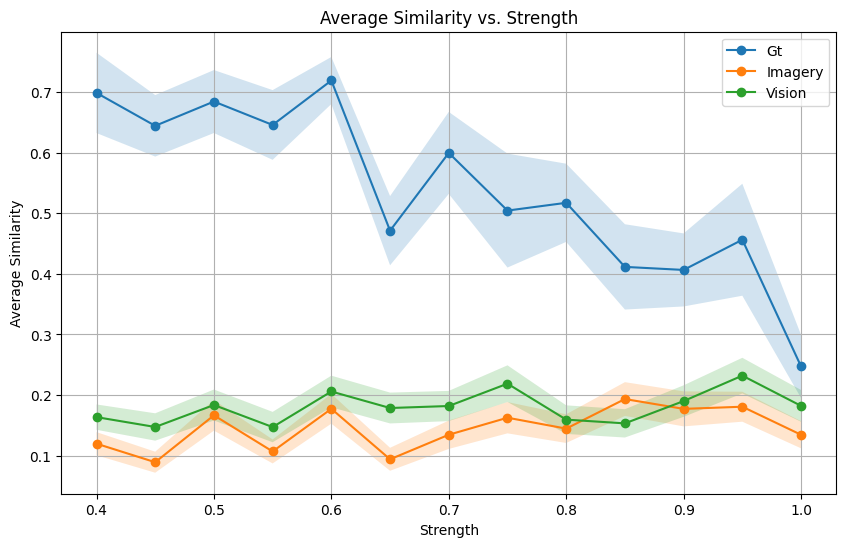

In [10]:
# Filter the dataframe by mode == "imagery"
# Plot average similarity for both "imagery" and "vision" modes
modes = ["gt", "imagery", "vision"]
plt.figure(figsize=(10, 6))

for mode in modes:
    filtered = filtered_df[filtered_df['mode'] == mode]
    
    strength_similarity_data = pd.DataFrame({
        'strength': pd.concat([filtered['stim2_strength'], filtered['stim3_strength']], ignore_index=True),
        'similarity': pd.concat([filtered['stim2_similarity'], filtered['stim3_similarity']], ignore_index=True)
    })
    
    average_similarity = strength_similarity_data.groupby('strength', as_index=False).agg(
        similarity_mean=('similarity', 'mean'),
        similarity_std=('similarity', 'std'),
        count=('similarity', 'count')
    )
    average_similarity['similarity_se'] = average_similarity['similarity_std'] / average_similarity['count']**0.5
    
    plt.plot(
        average_similarity['strength'],
        average_similarity['similarity_mean'],
        marker='o',
        label=mode.capitalize()
    )
    plt.fill_between(
        average_similarity['strength'],
        average_similarity['similarity_mean'] - average_similarity['similarity_se'],
        average_similarity['similarity_mean'] + average_similarity['similarity_se'],
        alpha=0.2
    )

plt.xlabel('Strength')
plt.ylabel('Average Similarity')
plt.title('Average Similarity vs. Strength')
plt.legend()
plt.grid(True)
plt.show()


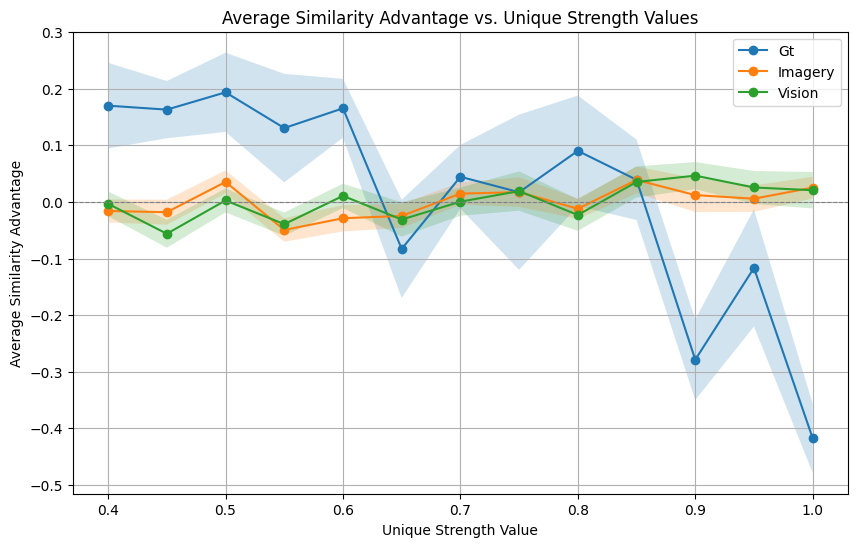

In [12]:
# Define the modes to plot
modes = ["gt", "imagery", "vision"]

# Extract unique strength values across both modes
unique_strength_values = np.unique(np.concatenate([filtered_df['stim2_strength'], filtered_df['stim3_strength']]))
unique_strength_values.sort()

# Initialize dictionaries to store means and standard errors
mean_diffs = {mode: [] for mode in modes}
se_diffs = {mode: [] for mode in modes}

# Calculate mean and standard error for each mode and strength
for mode in modes:
    for strength in unique_strength_values:
        # Filter rows for the current mode and strength
        relevant_rows = filtered_df[
            (filtered_df['mode'] == mode) & 
            ((filtered_df['stim2_strength'] == strength) | (filtered_df['stim3_strength'] == strength))
        ].copy()
        
        if not relevant_rows.empty:
            # Compute signed similarity difference
            relevant_rows['signed_similarity_diff'] = relevant_rows.apply(
                lambda row: row['stim2_similarity'] - row['stim3_similarity']
                if row['stim2_strength'] == strength else row['stim3_similarity'] - row['stim2_similarity'], 
                axis=1
            )
            
            # Calculate mean and standard error
            mean_diff = relevant_rows['signed_similarity_diff'].mean()
            se_diff = relevant_rows['signed_similarity_diff'].sem()
        else:
            mean_diff = np.nan
            se_diff = np.nan
        
        mean_diffs[mode].append(mean_diff)
        se_diffs[mode].append(se_diff)

# Plotting
plt.figure(figsize=(10, 6))

for mode in modes:
    plt.plot(
        unique_strength_values, 
        mean_diffs[mode], 
        marker='o', 
        label=mode.capitalize()
    )
    plt.fill_between(
        unique_strength_values, 
        np.array(mean_diffs[mode]) - np.array(se_diffs[mode]),
        np.array(mean_diffs[mode]) + np.array(se_diffs[mode]),
        alpha=0.2
    )

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Unique Strength Value')
plt.ylabel('Average Similarity Advantage')
plt.title('Average Similarity Advantage vs. Unique Strength Values')
plt.legend()
plt.grid(True)
plt.show()


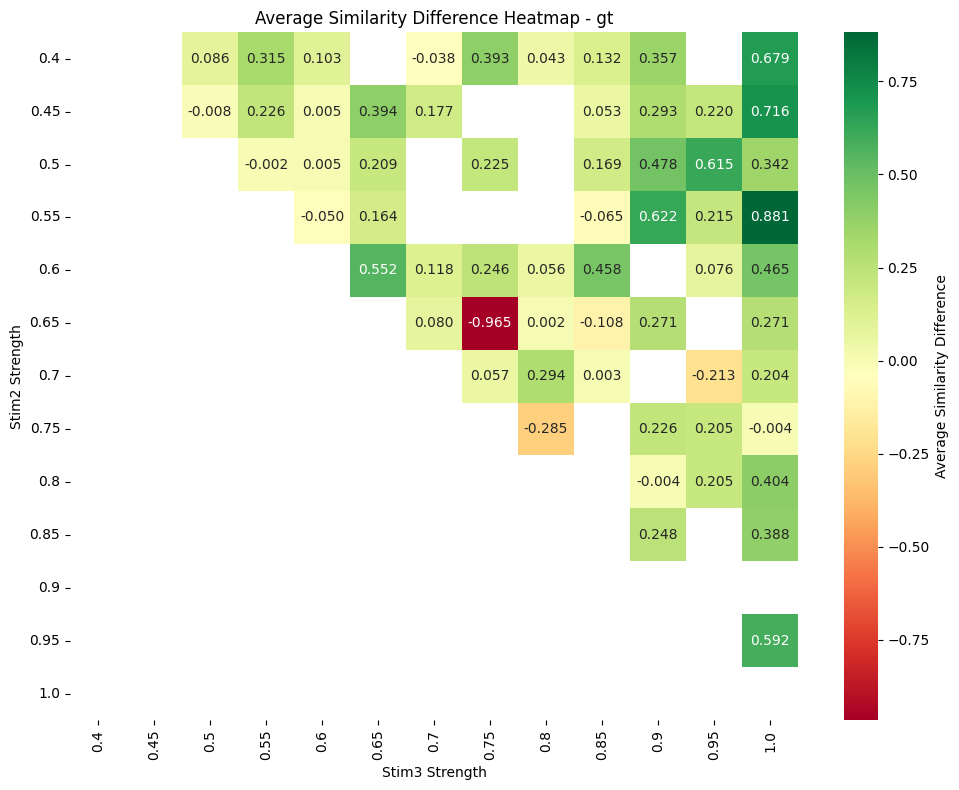

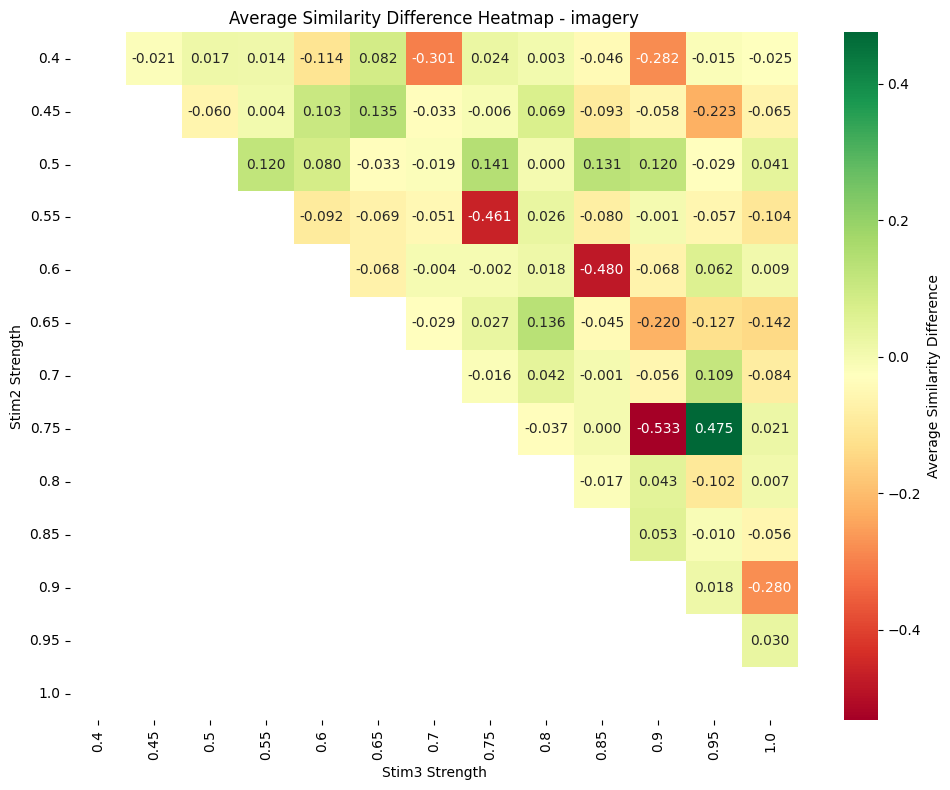

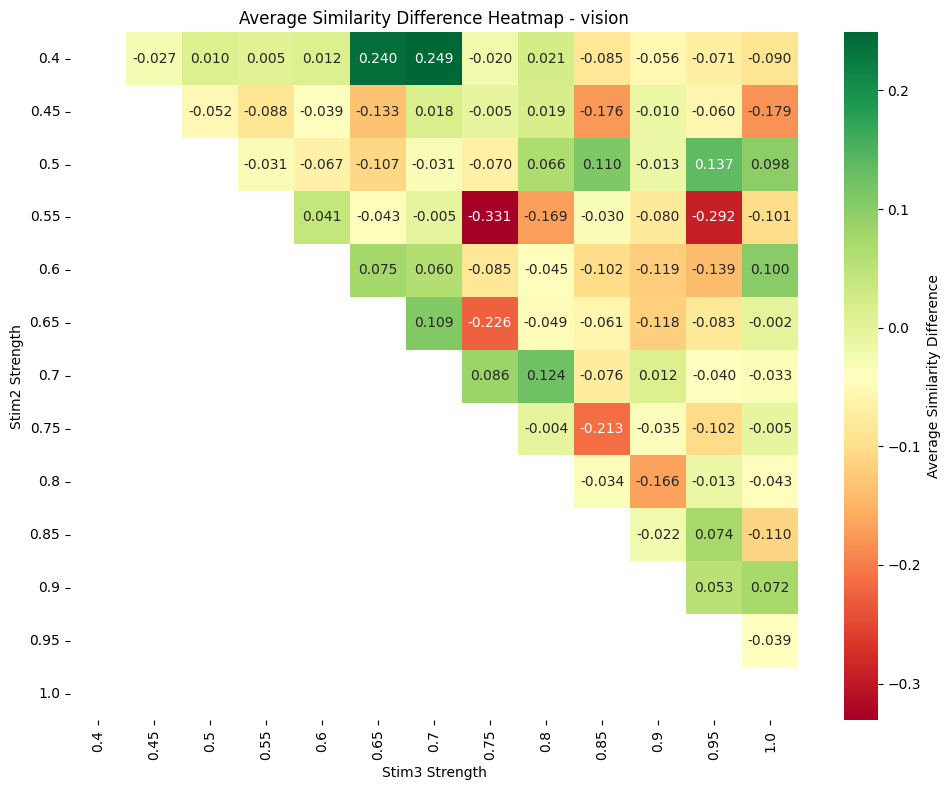

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# Extract unique strength values across both modes
unique_strength_values = np.unique(np.concatenate([filtered_df['stim2_strength'], filtered_df['stim3_strength']]))
unique_strength_values.sort()
modes = ["gt", "imagery", "vision"]
for mode in modes:
    # Initialize a matrix to store average differences
    heatmap_matrix = pd.DataFrame(np.nan, index=unique_strength_values, columns=unique_strength_values)
    
    for s1 in unique_strength_values:
        for s2 in unique_strength_values:
            if s1 <= s2:
                # Filter trials for the current mode and strength combination
                subset = filtered_df[
                    (filtered_df['mode'] == mode) &
                    (filtered_df['stim2_strength'] == s1) &
                    (filtered_df['stim3_strength'] == s2)
                ]
                if not subset.empty:
                    # Compute the average difference in similarity scores
                    avg_diff_1 = (subset['stim2_similarity'] - subset['stim3_similarity']).mean()
                else:
                    avg_diff_1 = np.nan
                
                if s1 != s2:
                    # Filter trials for the reversed strength combination
                    subset_reversed = filtered_df[
                        (filtered_df['mode'] == mode) &
                        (filtered_df['stim2_strength'] == s2) &
                        (filtered_df['stim3_strength'] == s1)
                    ]
                    if not subset_reversed.empty:
                        # Compute the average difference and invert it
                        avg_diff_2 = (subset_reversed['stim2_similarity'] - subset_reversed['stim3_similarity']).mean()
                        avg_diff_2 = -avg_diff_2
                    else:
                        avg_diff_2 = np.nan
                else:
                    avg_diff_2 = np.nan
                
                # Combine the two averages
                if not np.isnan(avg_diff_1) and not np.isnan(avg_diff_2):
                    combined_avg = (avg_diff_1 + avg_diff_2) / 2
                elif not np.isnan(avg_diff_1):
                    combined_avg = avg_diff_1
                elif not np.isnan(avg_diff_2):
                    combined_avg = avg_diff_2
                else:
                    combined_avg = np.nan
                
                heatmap_matrix.at[s1, s2] = combined_avg
    
    # Create a mask for the lower triangle
    mask = np.tril(np.ones_like(heatmap_matrix, dtype=bool))
    
    # Plot the heatmap using seaborn
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        heatmap_matrix,
        cmap='RdYlGn',
        mask=mask,
        annot=True,
        fmt=".3f",
        cbar_kws={'label': 'Average Similarity Difference'}
    )
    plt.title(f'Average Similarity Difference Heatmap - {mode}')
    plt.xlabel('Stim3 Strength')
    plt.ylabel('Stim2 Strength')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

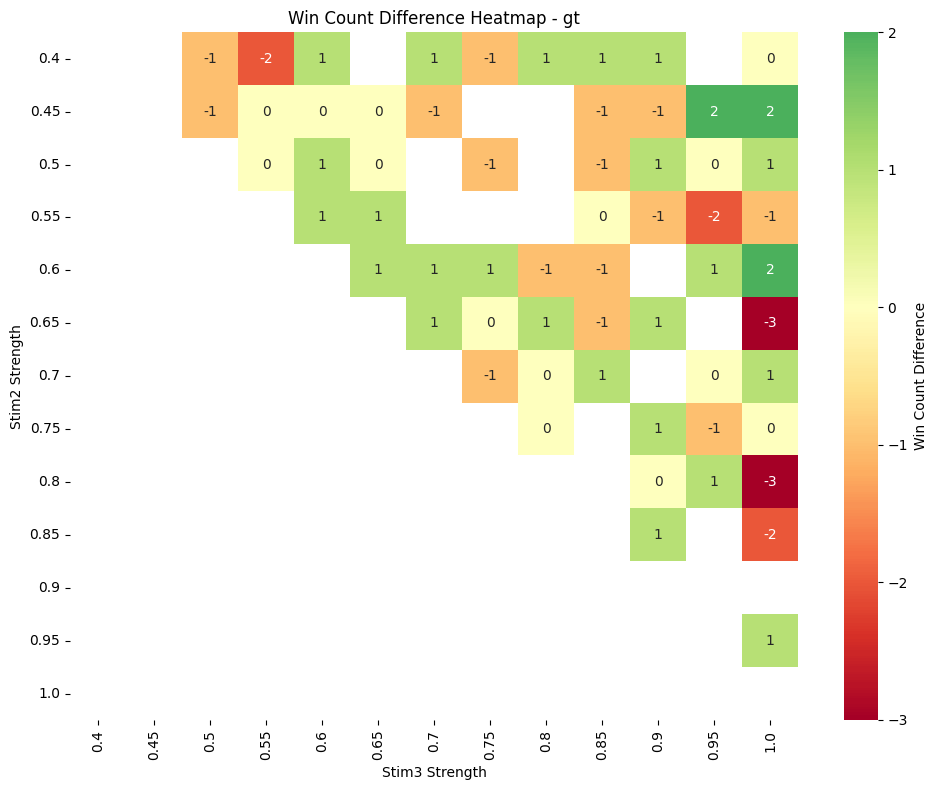

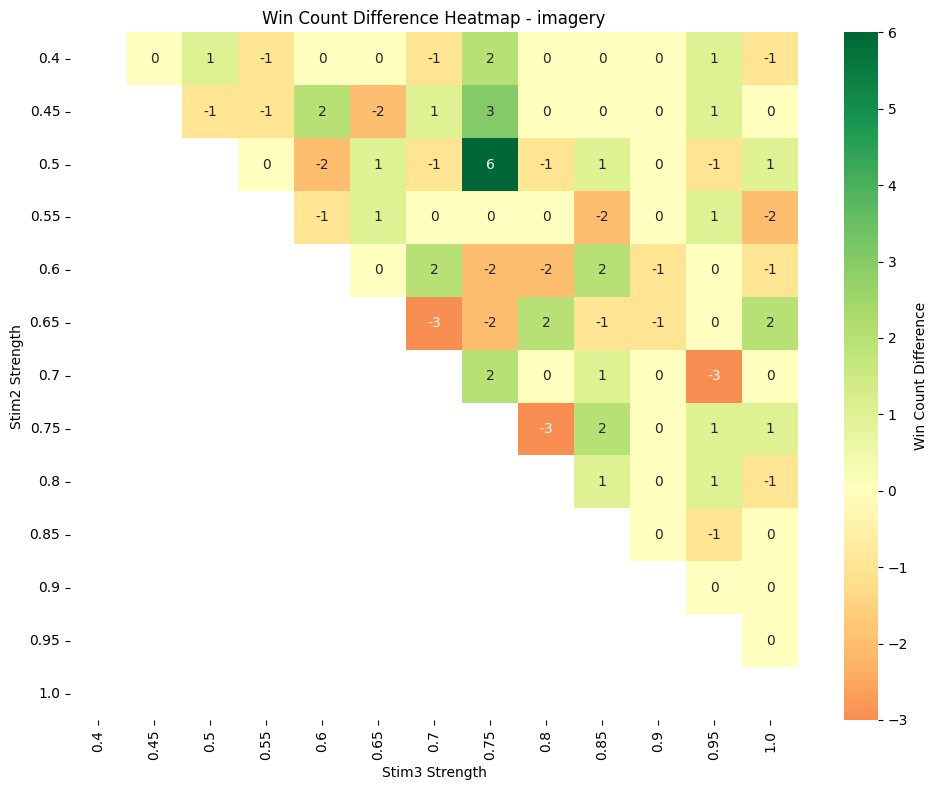

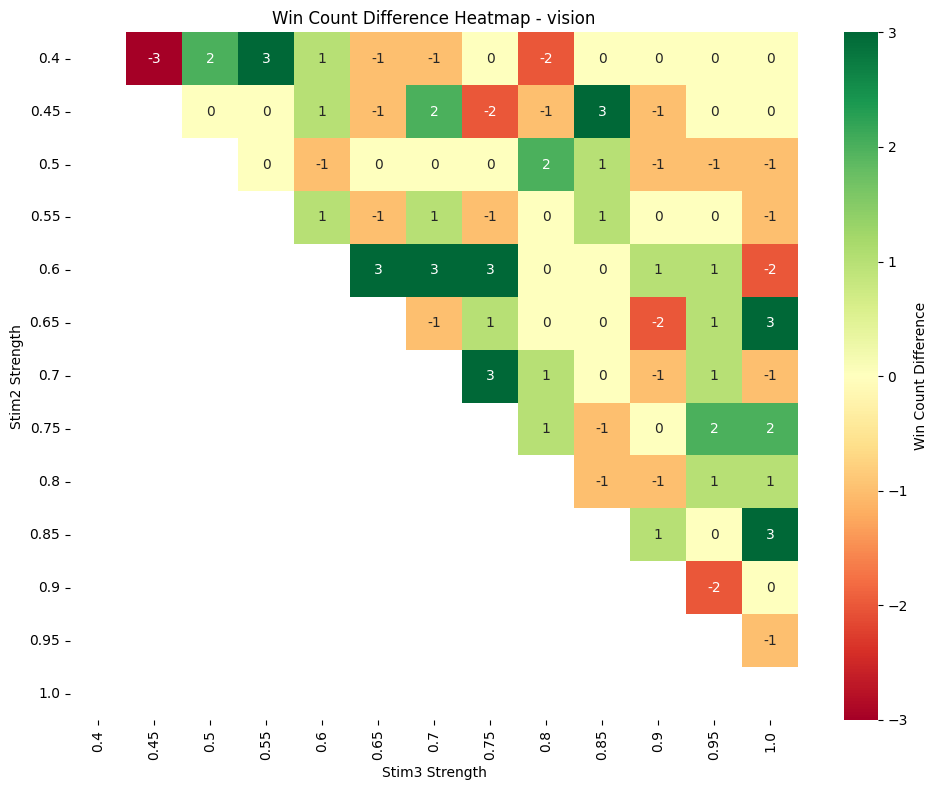

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Extract unique strength values across both modes
unique_strength_values = np.unique(np.concatenate([filtered_df['stim2_strength'], filtered_df['stim3_strength']]))
unique_strength_values.sort()
modes = ["gt", "imagery", "vision"]

for mode in modes:
    # Initialize a matrix to store win counts
    heatmap_matrix = pd.DataFrame(np.nan, index=unique_strength_values, columns=unique_strength_values)
    
    for s1 in unique_strength_values:
        for s2 in unique_strength_values:
            if s1 <= s2:
                # Filter trials for the current mode and strength combination
                subset = filtered_df[
                    (filtered_df['mode'] == mode) &
                    (filtered_df['stim2_strength'] == s1) &
                    (filtered_df['stim3_strength'] == s2)
                ]
                if not subset.empty:
                    # Calculate win count for stim2
                    win_count_1 = (subset['stim2_similarity'] > subset['stim3_similarity']).sum()
                else:
                    win_count_1 = np.nan
                
                if s1 != s2:
                    # Filter trials for the reversed strength combination
                    subset_reversed = filtered_df[
                        (filtered_df['mode'] == mode) &
                        (filtered_df['stim2_strength'] == s2) &
                        (filtered_df['stim3_strength'] == s1)
                    ]
                    if not subset_reversed.empty:
                        # Calculate win count for stim3
                        win_count_2 = (subset_reversed['stim3_similarity'] > subset_reversed['stim2_similarity']).sum()
                    else:
                        win_count_2 = np.nan
                else:
                    win_count_2 = np.nan
                
                # Combine the two win counts
                if not np.isnan(win_count_1) and not np.isnan(win_count_2):
                    combined_win_count = win_count_1 - win_count_2
                elif not np.isnan(win_count_1):
                    combined_win_count = win_count_1
                elif not np.isnan(win_count_2):
                    combined_win_count = -win_count_2
                else:
                    combined_win_count = np.nan
                
                heatmap_matrix.at[s1, s2] = combined_win_count
    
    # Create a mask for the lower triangle
    mask = np.tril(np.ones_like(heatmap_matrix, dtype=bool))
    
    # Plot the heatmap using seaborn
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        heatmap_matrix,
        cmap='RdYlGn',
        mask=mask,
        annot=True,
        fmt=".0f",
        center=0,
        cbar_kws={'label': 'Win Count Difference'}
    )
    plt.title(f'Win Count Difference Heatmap - {mode}')
    plt.xlabel('Stim3 Strength')
    plt.ylabel('Stim2 Strength')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Calculate the average similarity and confidence for each method and stimtype
averages = []
for method in df_trial_exp2['method'].unique():
    # for stimtype in df_trial_exp2['stimtype'].unique():
    category_df = df_trial_exp2[(df_trial_exp2["method"] == method) & (df_trial_exp2["stimtype"] == stimtype)]
    avg_vision_similarity = category_df['target_similarity'].mean()
    avg_imagery_similarity = category_df['distractor_similarity'].mean()
    avg_vision_confidence = category_df['target_confidence'].mean()
    avg_imagery_confidence = category_df['distractor_confidence'].mean()
    print(f"Method: {method}, Average Vision Similarity: {avg_vision_similarity:.3f}, Average Vision Confidence: {avg_vision_confidence:.3f}, Average Imagery Similarity: {avg_imagery_similarity:.3f}, Average Imagery Confidence: {avg_imagery_confidence:.3f}")
    averages.append((method, stimtype, avg_vision_similarity, avg_imagery_similarity))

# Create a list of methods and their corresponding average similarity values for vision and imagery
methods = []
vision_similarities = []
imagery_similarities = []

for method, _, avg_vision_similarity, avg_imagery_similarity in averages:
    if method == "boi-v2.1":
        method_label = "mindeye\n + BOI"
    elif method == "boi-v2.3":
        method_label = "braindiffuser\n + BOI"
    else:
        method_label = method
    methods.append(method_label)
    vision_similarities.append(avg_vision_similarity)
    imagery_similarities.append(avg_imagery_similarity)

# Set the width of the bars
bar_width = 0.35

# Set the positions of the bars on the X-axis
r1 = np.arange(len(methods))
r2 = [x + bar_width for x in r1]

# Plot the bars
plt.bar(r1, vision_similarities, color='blue', width=bar_width, label='Vision')
plt.bar(r2, imagery_similarities, color='orange', width=bar_width, label='Imagery')

# Add labels and title
plt.xlabel('Methods')
plt.ylabel('Average Similarity')
plt.title('Experiment 2: Average Similarity for Vision and Imagery')
plt.xticks([r + bar_width/2 for r in range(len(methods))], methods)

# Add legend
plt.legend()

# Show the plot
plt.show()



In [ ]:
# Experiment 3 is brain-optimized inference vs base model, BOI trials are marked as "target", base trials are marked as "distractor"

df_trial_exp3 = df_trial_exp[(df_trial_exp['experiment'] == 3)]
print(df_trial_exp3['method'].unique())
for method in df_trial_exp3['method'].unique():
    for mode in df_trial_exp3['mode'].unique():
        category_df = df_trial_exp3[(df_trial_exp3["mode"] == mode) & (df_trial_exp3["method"] == method)]
        avg_boi_similarity = category_df['target_similarity'].mean()
        avg_base_similarity = category_df['distractor_similarity'].mean()
        avg_boi_confidence = category_df['target_confidence'].mean()
        avg_base_confidence = category_df['distractor_confidence'].mean()
        print(f"Method: {method}, Mode: {mode}, Average BOI Similarity: {avg_boi_similarity:.3f}, Average BOI Confidence: {avg_boi_confidence:.3f}, Average Base Model Similarity: {avg_base_similarity:.3f}, Average Base Model Confidence: {avg_base_confidence:.3f}")

import matplotlib.pyplot as plt

# Data
methods = df_trial_exp3['method'].unique()
modes = df_trial_exp3['mode'].unique()
avg_boi_similarity = []
avg_base_similarity = []
avg_boi_confidence = []
avg_base_confidence = []

# Calculate averages
for method in methods:
    for mode in modes:
        category_df = df_trial_exp3[(df_trial_exp3["mode"] == mode) & (df_trial_exp3["method"] == method)]
        avg_boi_similarity.append(category_df['target_similarity'].mean())
        avg_base_similarity.append(category_df['distractor_similarity'].mean())
        avg_boi_confidence.append(category_df['target_confidence'].mean())
        avg_base_confidence.append(category_df['distractor_confidence'].mean())

# Plotting
x = range(len(methods) * len(modes))
width = 0.35

fig, ax = plt.subplots()
rects1 = ax.bar(x, avg_boi_similarity, width, label='BOI Similarity')
rects2 = ax.bar([i + width for i in x], avg_base_similarity, width, label='Base Model Similarity')

# Add labels, title, and legend
ax.set_ylabel('Average Similarity')
ax.set_title('Experiment 3: BOI vs Base Model Similarity')
ax.set_xticks([i + width/2 for i in x])
ax.set_xticklabels([f'{method}\n{mode}' for method in methods for mode in modes])
ax.legend()

# Show the plot
plt.show()


In [ ]:
      mode    base method  Statistic   P-value  Avg_Percentage_Improvement_Corrected  
0  imagery  braindiffuser   4.852082  0.000002   28.047254%
1  imagery        mindeye  -0.167633  0.866943   -0.796622%
2   vision  braindiffuser   3.475545  0.000557   15.967266% 
3   vision        mindeye   1.740338  0.082451   5.790017%
